In [2]:
import pandas as pd

In [3]:
train = pd.read_csv("../Data/train.csv")
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
train.set_index('PassengerId', inplace=True)
train.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [5]:
train.tail()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [6]:
train.shape

(891, 11)

In [7]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 1 to 891
Data columns (total 11 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  891 non-null    int64  
 1   Pclass    891 non-null    int64  
 2   Name      891 non-null    str    
 3   Sex       891 non-null    str    
 4   Age       714 non-null    float64
 5   SibSp     891 non-null    int64  
 6   Parch     891 non-null    int64  
 7   Ticket    891 non-null    str    
 8   Fare      891 non-null    float64
 9   Cabin     204 non-null    str    
 10  Embarked  889 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 111.9 KB


In [17]:
train.head()
train.Survived.unique()
train.Pclass.unique()
train.Embarked.unique()

<ArrowStringArray>
['S', 'C', 'Q', nan]
Length: 4, dtype: str

<Axes: ylabel='Frequency'>

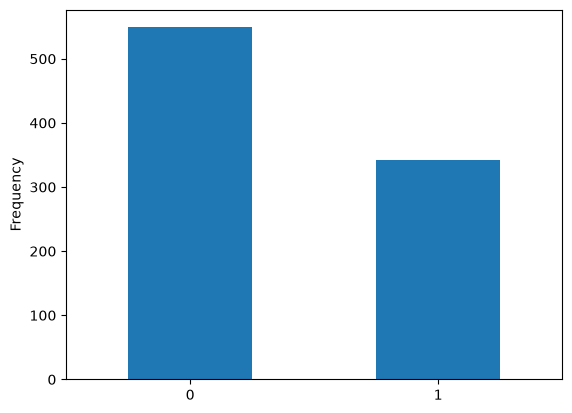

In [ ]:
# Survived의 빈도수 확인
train.Survived.value_counts().plot(kind='bar') # 이미 빈도수 값에서 그래프를 만드는 방법

train.Survived.plot(    # 그냥 데이터에서 빈도수 그래프를 만드는 방법
    kind='hist'
)

In [29]:
train.Survived.value_counts()

Survived
0    549
1    342
Name: count, dtype: int64

In [ ]:
342/549 # 0.6까지가 허용 범위 최댓값

0.6229508196721312

In [54]:
train[['Sex','Pclass','Survived']].head()


,Sex,Pclass,Survived
PassengerId,,,
1,male,3,0
2,female,1,1
3,female,3,1
4,female,1,1
5,male,3,0


In [59]:
train.loc[[1,3,7,13]]

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
13,0,3,"Saundercock, Mr. William Henry",male,20.0,0,0,A/5. 2151,8.0500,NaN,S


In [57]:
train.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


----
#### Boolean Indexing

In [72]:
# 타이타닉호에 남성 승선 인원수?
print(len(train[train.Sex == 'male']))
print(train[train.Sex == 'male'].shape[0])
print(train[train.Sex == 'male'].Survived.count()) # 결측치는 계산이 안됨

577
577
577


In [89]:
# 운임(Fare)을 20달러 이상을 지불한 사람의 수는?

print(len(train[train.Fare >= 20]))
print(train[train.Fare >= 20].shape[0])
print(train[train.Fare >= 20].Survived.count())

376
376
376


In [95]:
# 운임을 평균 운임이상으로 지급한 사람의 수는?

train[train.Fare >= train.Fare.mean()].shape[0]

211

In [104]:
# 운임을 평균 이상으로 지급한 사람들 중 1등급 객실을 사용한 사람의 수는?

train[(train.Fare >= train.Fare.mean()) & (train.Pclass == 1)].shape[0]


159

In [105]:
# 1등급 객실을 사용한 인원 수?
train[train.Pclass == 1].shape[0]

216

In [122]:
# 최대 운임을 지불한 사람은?
train[train.Fare == train.Fare.max()]

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C
680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C
738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C


In [130]:
train[train['Ticket'] == 'PC 17755']

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C
680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C
738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C


In [134]:
train[train['Ticket'] == '239853']

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
278,0,2,"Parkes, Mr. Francis ""Frank""",male,NaN,0,0,239853,0.0,NaN,S
414,0,2,"Cunningham, Mr. Alfred Fleming",male,NaN,0,0,239853,0.0,NaN,S
467,0,2,"Campbell, Mr. William",male,NaN,0,0,239853,0.0,NaN,S


In [133]:
train[train.Fare == train.Fare.min()]

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
180,0,3,"Leonard, Mr. Lionel",male,36.0,0,0,LINE,0.0,NaN,S
264,0,1,"Harrison, Mr. William",male,40.0,0,0,112059,0.0,B94,S
272,1,3,"Tornquist, Mr. William Henry",male,25.0,0,0,LINE,0.0,NaN,S
278,0,2,"Parkes, Mr. Francis ""Frank""",male,NaN,0,0,239853,0.0,NaN,S
303,0,3,"Johnson, Mr. William Cahoone Jr",male,19.0,0,0,LINE,0.0,NaN,S
414,0,2,"Cunningham, Mr. Alfred Fleming",male,NaN,0,0,239853,0.0,NaN,S
467,0,2,"Campbell, Mr. William",male,NaN,0,0,239853,0.0,NaN,S
482,0,2,"Frost, Mr. Anthony Wood ""Archie""",male,NaN,0,0,239854,0.0,NaN,S
598,0,3,"Johnson, Mr. Alfred",male,49.0,0,0,LINE,0.0,NaN,S


In [143]:
# 중복되는 티켓 번호를 가진 승객만 선택
same_ticket = train[train.duplicated('Ticket', keep=False)]
same_ticket.sort_values('Ticket')

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
258,1,1,"Cherry, Miss. Gladys",female,30.0,0,0,110152,86.500,B77,S
505,1,1,"Maioni, Miss. Roberta",female,16.0,0,0,110152,86.500,B79,S
760,1,1,"Rothes, the Countess. of (Lucy Noel Martha Dye...",female,33.0,0,0,110152,86.500,B77,S
263,0,1,"Taussig, Mr. Emil",male,52.0,1,1,110413,79.650,E67,S
559,1,1,"Taussig, Mrs. Emil (Tillie Mandelbaum)",female,39.0,1,1,110413,79.650,E67,S
...,...,...,...,...,...,...,...,...,...,...,...
148,0,3,"Ford, Miss. Robina Maggie ""Ruby""",female,9.0,2,2,W./C. 6608,34.375,NaN,S
437,0,3,"Ford, Miss. Doolina Margaret ""Daisy""",female,21.0,2,2,W./C. 6608,34.375,NaN,S
737,0,3,"Ford, Mrs. Edward (Margaret Ann Watson)",female,48.0,1,3,W./C. 6608,34.375,NaN,S


In [ ]:
# 각 항구(c,s,q)에서 승선한 사람의 인원수?
train[train.Embarked == 'C'].shape[0]
train[train.Embarked == 'S'].shape[0]
train[train.Embarked == 'Q'].shape[0]

train.groupby("Embarked").size() # 해당 그룹의 각각의 size

Embarked
C    168
Q     77
S    644
dtype: int64

<Axes: xlabel='Embarked'>

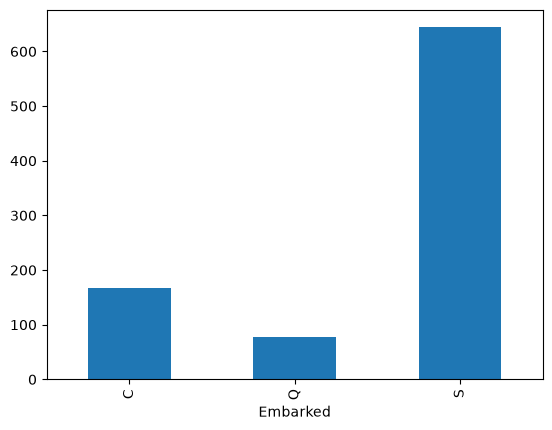

In [153]:
train.groupby("Embarked")['Survived'].count().plot(kind='bar')

In [157]:
# Ticket에 STON이란 문자가 있는 데이터 추출하기
train[train.Ticket.str.contains("STON")]

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.925,NaN,S
116,0,3,"Pekoniemi, Mr. Edvard",male,21.0,0,0,STON/O 2. 3101294,7.925,NaN,S
143,1,3,"Hakkarainen, Mrs. Pekka Pietari (Elin Matilda ...",female,24.0,1,0,STON/O2. 3101279,15.850,NaN,S
174,0,3,"Sivola, Mr. Antti Wilhelm",male,21.0,0,0,STON/O 2. 3101280,7.925,NaN,S
217,1,3,"Honkanen, Miss. Eliina",female,27.0,0,0,STON/O2. 3101283,7.925,NaN,S
244,0,3,"Maenpaa, Mr. Matti Alexanteri",male,22.0,0,0,STON/O 2. 3101275,7.125,NaN,S
383,0,3,"Tikkanen, Mr. Juho",male,32.0,0,0,STON/O 2. 3101293,7.925,NaN,S
401,1,3,"Niskanen, Mr. Juha",male,39.0,0,0,STON/O 2. 3101289,7.925,NaN,S
404,0,3,"Hakkarainen, Mr. Pekka Pietari",male,28.0,1,0,STON/O2. 3101279,15.850,NaN,S


In [160]:
# Age가 NaN인 데이터
train[train.Age.isnull()]

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
18,1,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S
20,1,3,"Masselmani, Mrs. Fatima",female,NaN,0,0,2649,7.2250,NaN,C
27,0,3,"Emir, Mr. Farred Chehab",male,NaN,0,0,2631,7.2250,NaN,C
29,1,3,"O'Dwyer, Miss. Ellen ""Nellie""",female,NaN,0,0,330959,7.8792,NaN,Q
...,...,...,...,...,...,...,...,...,...,...,...
860,0,3,"Razi, Mr. Raihed",male,NaN,0,0,2629,7.2292,NaN,C
864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.5500,NaN,S
869,0,3,"van Melkebeke, Mr. Philemon",male,NaN,0,0,345777,9.5000,NaN,S


In [161]:
# Age가 NaN이 아닌 데이터
train[train.Age.notnull()]

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
886,0,3,"Rice, Mrs. William (Margaret Norton)",female,39.0,0,5,382652,29.1250,NaN,Q
887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S


In [162]:
# Age가 NaN이거나 Fare가 NaN인 데이터 추출

train[(train.Age.isnull()) | (train.Fare.isnull())]

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
18,1,2,"Williams, Mr. Charles Eugene",male,NaN,0,0,244373,13.0000,NaN,S
20,1,3,"Masselmani, Mrs. Fatima",female,NaN,0,0,2649,7.2250,NaN,C
27,0,3,"Emir, Mr. Farred Chehab",male,NaN,0,0,2631,7.2250,NaN,C
29,1,3,"O'Dwyer, Miss. Ellen ""Nellie""",female,NaN,0,0,330959,7.8792,NaN,Q
...,...,...,...,...,...,...,...,...,...,...,...
860,0,3,"Razi, Mr. Raihed",male,NaN,0,0,2629,7.2292,NaN,C
864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.5500,NaN,S
869,0,3,"van Melkebeke, Mr. Philemon",male,NaN,0,0,345777,9.5000,NaN,S


In [184]:
# 최연소 승선객의 이름?
train[train.Age == train.Age.min()].Name

PassengerId
804    Thomas, Master. Assad Alexander
Name: Name, dtype: str

In [174]:
# 최고령자의 정보
train[train.Age == train.Age.max()]

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
PassengerId,,,,,,,,,,,
631,1,1,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,27042,30.0,A23,S


In [188]:
# 성별 생존

train.groupby(['Survived', 'Sex']).size()

Survived  Sex   
0         female     81
          male      468
1         female    233
          male      109
dtype: int64

---
#### Feature Engineering
: 컬럼 추가하기 및 수정하기

In [190]:
# Category 컬럼추가
'Category' in train.columns

False

In [199]:
train['Category'] = 'Titanic'
train.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Category
PassengerId,,,,,,,,,,,,
1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S,Titanic
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C,Titanic
3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S,Titanic
4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S,Titanic
5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S,Titanic


In [ ]:
# FamilySize = SibSp + Parch + 1

FamilySize = train.SibSp + train.Parch + 1

train['FamilySize'] = FamilySize
train.head()

train['FamilySize'].sum()

np.int64(1697)

In [210]:
# 최대 Family Size?
train[train.FamilySize == FamilySize.max()]

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,Category,FamilySize
PassengerId,,,,,,,,,,,,,
160,0,3,"Sage, Master. Thomas Henry",male,NaN,8,2,CA. 2343,69.55,NaN,S,Titanic,11
181,0,3,"Sage, Miss. Constance Gladys",female,NaN,8,2,CA. 2343,69.55,NaN,S,Titanic,11
202,0,3,"Sage, Mr. Frederick",male,NaN,8,2,CA. 2343,69.55,NaN,S,Titanic,11
325,0,3,"Sage, Mr. George John Jr",male,NaN,8,2,CA. 2343,69.55,NaN,S,Titanic,11
793,0,3,"Sage, Miss. Stella Anna",female,NaN,8,2,CA. 2343,69.55,NaN,S,Titanic,11
847,0,3,"Sage, Mr. Douglas Bullen",male,NaN,8,2,CA. 2343,69.55,NaN,S,Titanic,11
864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.55,NaN,S,Titanic,11


In [213]:
# Embarked가 C인 것과 아닌 것으로 구분
# Nationality_FR , Nationality_UK
train['Nationality_FR'] = train.Embarked == "C"
train['Nationality_UK'] = train.Embarked != "C"
train[['Embarked', 'Nationality_FR', 'Nationality_UK']].head()

,Embarked,Nationality_FR,Nationality_UK
PassengerId,,,
1,S,False,True
2,C,True,False
3,S,False,True
4,S,False,True
5,S,False,True


In [217]:
# Nationality 컬럼에 France, England
train.loc[train.Embarked == "C","Nationality"] = "France"
train.loc[train.Embarked != "C","Nationality"] = "England"
train[['Embarked', 'Nationality']].head()

,Embarked,Nationality
PassengerId,,
1,S,England
2,C,France
3,S,England
4,S,England
5,S,England


In [218]:
# Fare에 대해 Category로 나누기
train.Fare.describe()

count    891.000000
mean      32.204208
std       49.693429
min        0.000000
25%        7.910400
50%       14.454200
75%       31.000000
max      512.329200
Name: Fare, dtype: float64

In [219]:
# 2분위와 3분위의 근사 정수치로 Fare 분류 컬럼 만들기
train['LowFare'] = train.Fare < 15
train['MediumFare'] = (train.Fare >= 15) & (train.Fare < 30)
train['HighFare'] = train.Fare >= 30
train[['Fare', 'LowFare', 'MediumFare', 'HighFare']].head()

,Fare,LowFare,MediumFare,HighFare
PassengerId,,,,
1,7.2500,True,False,False
2,71.2833,False,False,True
3,7.9250,True,False,False
4,53.1000,False,False,True
5,8.0500,True,False,False


In [227]:
train.loc[train.Fare < 15, 'FareType'] = 'Low'
train.loc[(train.Fare >= 15) & (train.Fare < 30), 'FareType'] = 'Medium'
train.loc[train.Fare >= 30, 'FareType'] =  'High'

train[['Fare', 'FareType']].head()

,Fare,FareType
PassengerId,,
1,7.2500,Low
2,71.2833,High
3,7.9250,Low
4,53.1000,High
5,8.0500,Low


In [225]:
# Python의 함수를 이용하여 처리하기
def check_fare_type(fare):
    if fare < 15:
        return 'Low'
    elif fare >= 15 and fare < 30:
        return 'Medium'
    else:
        return 'High'

In [ ]:
train['FareType2'] = train.Fare.apply(check_fare_type) # apply -> 중요함
train[['Fare', 'FareType2']].head()

,Fare,FareType2
PassengerId,,
1,7.2500,Low
2,71.2833,High
3,7.9250,Low
4,53.1000,High
5,8.0500,Low


In [228]:
def check_fare_type2(fare):
    if fare < 15:
        return 'Low'
    elif fare < 30:
        return 'Medium'
    else:
        return 'High'


train['FareType'] = train['Fare'].apply(check_fare_type2)

train[['Fare', 'FareType']].head()

,Fare,FareType
PassengerId,,
1,7.2500,Low
2,71.2833,High
3,7.9250,Low
4,53.1000,High
5,8.0500,Low


In [229]:
train.columns

Index(['Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket',
       'Fare', 'Cabin', 'Embarked', 'Category', 'FamilySize', 'Nationality_FR',
       'Nationality_UK', 'Nationality', 'LowFare', 'MediumFare', 'HighFare',
       'FareType', 'FareType2'],
      dtype='str')

In [230]:
train.to_csv("../Data/train_modified.csv")